In [5]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [1]:
!pip install kagglehub
import kagglehub

In [3]:
path = kagglehub.dataset_download("samuelpombourcq/formula-1-world-championship-1950-2026")


Using Colab cache for faster access to the 'formula-1-world-championship-1950-2026' dataset.


In [4]:
print(path)

/kaggle/input/formula-1-world-championship-1950-2026


LOAD


In [7]:
def load(name):
    return pd.read_csv(os.path.join(path, name), na_values=['\\N'])  # \N means missing in this dataset

results = load('results.csv')
races = load('races.csv')
drivers = load('drivers.csv')
constructors = load('constructors.csv')
status = load('status.csv')

ORGANISE

In [8]:
df = (results
      .merge(races[['raceId', 'year', 'name']].rename(columns={'name': 'race'}), on='raceId')
      .merge(drivers[['driverId', 'surname']], on='driverId')
      .merge(constructors[['constructorId', 'name']].rename(columns={'name': 'team'}), on='constructorId')
      .merge(status, on='statusId'))

df.head()

,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,...,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId,year,race,surname,team,status
0,1,1,1,1,2.0,1,1.0,1,1,9.0,...,NaN,NaN,NaN,NaN,1,1950,British Grand Prix,Farina,Alfa Romeo,Finished
1,2,1,2,1,3.0,2,2.0,2,2,6.0,...,NaN,NaN,NaN,NaN,1,1950,British Grand Prix,Fagioli,Alfa Romeo,Finished
2,3,1,3,1,4.0,4,3.0,3,3,4.0,...,NaN,NaN,NaN,NaN,1,1950,British Grand Prix,Parnell,Alfa Romeo,Finished
3,4,1,4,5,14.0,6,4.0,4,4,3.0,...,NaN,NaN,NaN,NaN,12,1950,British Grand Prix,Cabantous,Talbot-Lago,+2 Laps
4,5,1,5,5,15.0,9,5.0,5,5,2.0,...,NaN,NaN,NaN,NaN,12,1950,British Grand Prix,Rosier,Talbot-Lago,+2 Laps


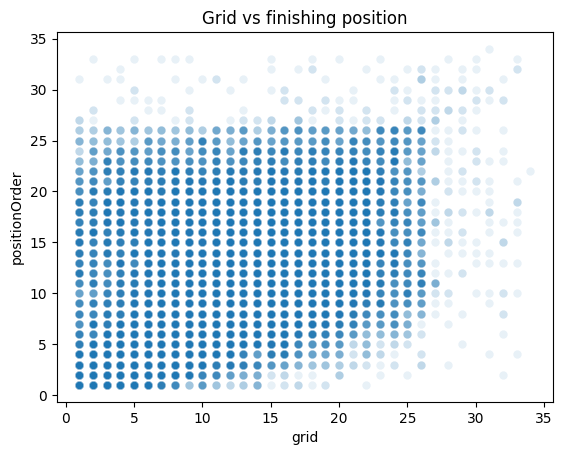

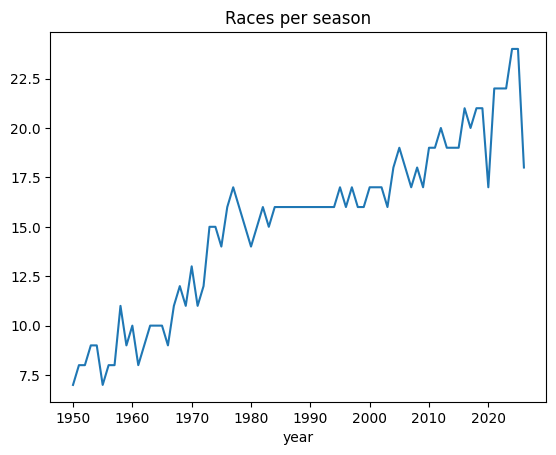

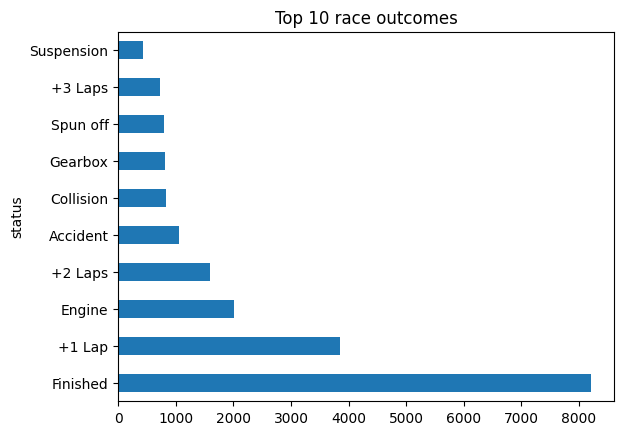

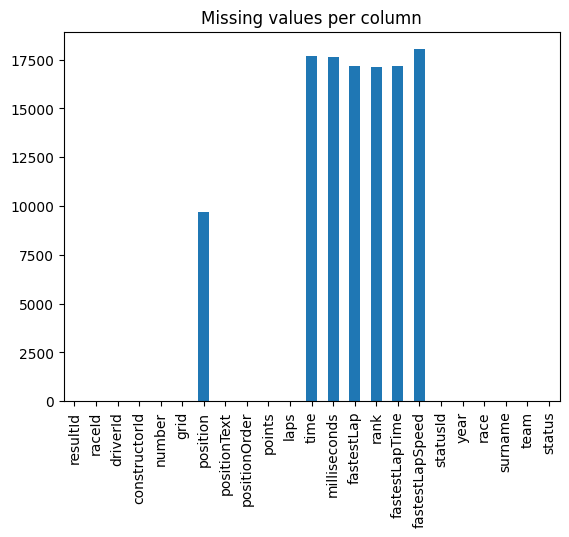

In [9]:

sns.scatterplot(x='grid', y='positionOrder', data=df[df['grid'] > 0], alpha=0.1)
plt.title('Grid vs finishing position')
plt.show()

df.groupby('year')['raceId'].nunique().plot()
plt.title('Races per season')
plt.show()

df['status'].value_counts().head(10).plot(kind='barh')
plt.title('Top 10 race outcomes')
plt.show()


df.isnull().sum().plot(kind='bar')
plt.title('Missing values per column')
plt.show()

Q1 - data already loaded and visualised


Q2 Yes ,since there is ample amount of data cavering a good amount of time period

In [10]:
print(df.shape)
print("Duplicates:", df.duplicated().sum())
print("Seasons covered:", df['year'].min(), "to", df['year'].max())

(26269, 23)
Duplicates: 0
Seasons covered: 1950 to 2026


Q3 - 23

In [11]:
print(df.shape[1], "columns")
print(df.columns.tolist())

23 columns
['resultId', 'raceId', 'driverId', 'constructorId', 'number', 'grid', 'position', 'positionText', 'positionOrder', 'points', 'laps', 'time', 'milliseconds', 'fastestLap', 'rank', 'fastestLapTime', 'fastestLapSpeed', 'statusId', 'year', 'race', 'surname', 'team', 'status']


Q4 - 26269

In [12]:
print(df.shape[0], "rows")

26269 rows


Q5 - floating points, integers and objects

In [13]:
print(df.dtypes)

resultId             int64
raceId               int64
driverId             int64
constructorId        int64
number             float64
grid                 int64
position           float64
positionText        object
positionOrder        int64
points             float64
laps                 int64
time                object
milliseconds       float64
fastestLap         float64
rank               float64
fastestLapTime      object
fastestLapSpeed    float64
statusId             int64
year                 int64
race                object
surname             object
team                object
status              object
dtype: object


Q6 - 8 columns

In [14]:
nulls = df.isnull().sum()
print(nulls[nulls > 0])


df[df['position'].isnull()][['year', 'race', 'surname', 'status']].head(10)

number                 6
position            9712
time               17655
milliseconds       17619
fastestLap         17161
rank               17137
fastestLapTime     17161
fastestLapSpeed    18031
dtype: int64


,year,race,surname,status
12,1950,British Grand Prix,Fangio,Oil leak
13,1950,British Grand Prix,Kelly,Not classified
14,1950,British Grand Prix,Bira,Out of fuel
15,1950,British Grand Prix,Murray,Engine
16,1950,British Grand Prix,Crossley,Transmission
17,1950,British Grand Prix,de Graffenried,Engine
18,1950,British Grand Prix,Chiron,Clutch
19,1950,British Grand Prix,Martin,Oil pressure
20,1950,British Grand Prix,Rolt,Gearbox
21,1950,British Grand Prix,Walker,Gearbox


Q7 - race attributes(features) vs the finishing order

In [15]:
features = ['grid', 'team', 'year', 'laps']
target = 'positionOrder'

df[features + [target]].head()

,grid,team,year,laps,positionOrder
0,1,Alfa Romeo,1950,70,1
1,2,Alfa Romeo,1950,70,2
2,4,Alfa Romeo,1950,70,3
3,6,Talbot-Lago,1950,68,4
4,9,Talbot-Lago,1950,68,5


Q8 - 7 features have missing values from rows 0-9

In [16]:
print((df.isnull().mean() * 100).round(1))  # % missing per column

df[df['fastestLapTime'].isnull()].index[:10]  # row numbers where it's missing

resultId            0.0
raceId              0.0
driverId            0.0
constructorId       0.0
number              0.0
grid                0.0
position           37.0
positionText        0.0
positionOrder       0.0
points              0.0
laps                0.0
time               67.2
milliseconds       67.1
fastestLap         65.3
rank               65.2
fastestLapTime     65.3
fastestLapSpeed    68.6
statusId            0.0
year                0.0
race                0.0
surname             0.0
team                0.0
status              0.0
dtype: float64


Index([0, 1, 2, 3, 4, 5, 6, 7, 8, 9], dtype='int64')

Q9 - we can make a question in the form of "Can we predict a driver's finishing order from their starting grid position?". The data complements the question.

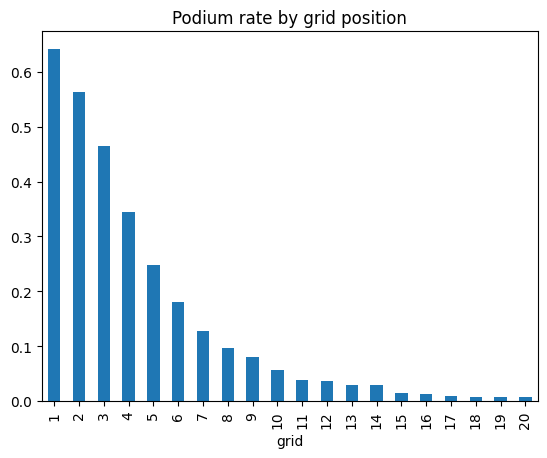

grid      0
podium    0
dtype: int64


In [17]:
df['podium'] = (df['positionOrder'] <= 3).astype(int)

# check the question is answerable: podium rate by starting position
df[df['grid'].between(1, 20)].groupby('grid')['podium'].mean().plot(kind='bar')
plt.title('Podium rate by grid position')
plt.show()

print(df[['grid', 'podium']].isnull().sum())  # both complete, so the data suits the question